In [2]:
import pandas as pd
from pathlib import Path

# Load anomaly detection results
file_path = Path("../data/processed/anomaly_detection_results.csv")

if not file_path.exists():
    raise FileNotFoundError(
        f"File not found: {file_path.resolve()}\n"
        "Check that Notebook 03 has saved its output."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nData types:")
display(df.dtypes)

Dataset loaded successfully!
Shape: (145366, 15)

Columns:
['Datetime', 'PJME_MW', 'Rolling_Median', 'Deviation', 'Rolling_MAD', 'Anomaly_Score', 'Potential_Anomaly', 'Hour', 'DayOfWeek', 'Seasonal_Baseline', 'Seasonal_Deviation', 'Seasonal_MAD', 'Seasonal_Anomaly_Score', 'Seasonal_Potential_Anomaly', 'Seasonal_Abs_Deviation']

First 5 rows:


,Datetime,PJME_MW,Rolling_Median,Deviation,Rolling_MAD,Anomaly_Score,Potential_Anomaly,Hour,DayOfWeek,Seasonal_Baseline,Seasonal_Deviation,Seasonal_MAD,Seasonal_Anomaly_Score,Seasonal_Potential_Anomaly,Seasonal_Abs_Deviation
0,2002-01-01 01:00:00,30393.0,NaN,NaN,NaN,NaN,False,1,1,NaN,NaN,NaN,NaN,False,NaN
1,2002-01-01 02:00:00,29265.0,NaN,NaN,NaN,NaN,False,2,1,NaN,NaN,NaN,NaN,False,NaN
2,2002-01-01 03:00:00,28357.0,NaN,NaN,NaN,NaN,False,3,1,NaN,NaN,NaN,NaN,False,NaN
3,2002-01-01 04:00:00,27899.0,NaN,NaN,NaN,NaN,False,4,1,NaN,NaN,NaN,NaN,False,NaN
4,2002-01-01 05:00:00,28057.0,NaN,NaN,NaN,NaN,False,5,1,NaN,NaN,NaN,NaN,False,NaN



Missing values:


Datetime                         0
PJME_MW                          0
Rolling_Median                  24
Deviation                       24
Rolling_MAD                     48
Anomaly_Score                   48
Potential_Anomaly                0
Hour                             0
DayOfWeek                        0
Seasonal_Baseline              672
Seasonal_Deviation             672
Seasonal_MAD                  1344
Seasonal_Anomaly_Score        1344
Seasonal_Potential_Anomaly       0
Seasonal_Abs_Deviation         672
dtype: int64


Data types:


Datetime                          str
PJME_MW                       float64
Rolling_Median                float64
Deviation                     float64
Rolling_MAD                   float64
Anomaly_Score                 float64
Potential_Anomaly                bool
Hour                            int64
DayOfWeek                       int64
Seasonal_Baseline             float64
Seasonal_Deviation            float64
Seasonal_MAD                  float64
Seasonal_Anomaly_Score        float64
Seasonal_Potential_Anomaly       bool
Seasonal_Abs_Deviation        float64
dtype: object

In [ ]:

total_rows = len(df)

simple_count = df["Potential_Anomaly"].sum()
seasonal_count = df["Seasonal_Potential_Anomaly"].sum()

simple_percentage = (simple_count / total_rows) * 100
seasonal_percentage = (seasonal_count / total_rows) * 100

print("===== ANOMALY DETECTION SUMMARY =====")
print(f"Total observations: {total_rows:,}")

print("\n1. Rolling Median + MAD Detector")
print(f"Potential anomalies: {simple_count:,}")
print(f"Percentage flagged: {simple_percentage:.2f}%")

print("\n2. Seasonality-Aware Detector")
print(f"Potential anomalies: {seasonal_count:,}")
print(f"Percentage flagged: {seasonal_percentage:.2f}%")

print("\n===== FLAG COUNTS =====")
display(
    df[["Potential_Anomaly", "Seasonal_Potential_Anomaly"]]
    .sum()
    .rename("Anomaly Count")
    .to_frame()
)

===== ANOMALY DETECTION SUMMARY =====
Total observations: 145,366

1. Rolling Median + MAD Detector
Potential anomalies: 5,061
Percentage flagged: 3.48%

2. Seasonality-Aware Detector
Potential anomalies: 6,048
Percentage flagged: 4.16%

===== FLAG COUNTS =====


,Anomaly Count
Potential_Anomaly,5061
Seasonal_Potential_Anomaly,6048


In [4]:
# Convert timestamp to datetime
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Inspect the strongest seasonal anomaly candidates
seasonal_candidates = (
    df[df["Seasonal_Potential_Anomaly"] == True]
    .sort_values("Seasonal_Abs_Deviation", ascending=False)
)

columns_to_show = [
    "Datetime",
    "PJME_MW",
    "Seasonal_Baseline",
    "Seasonal_Deviation",
    "Seasonal_Anomaly_Score",
    "Seasonal_Potential_Anomaly"
]

print("Top 15 strongest seasonal anomaly candidates:")
display(seasonal_candidates[columns_to_show].head(15))

Top 15 strongest seasonal anomaly candidates:


,Datetime,PJME_MW,Seasonal_Baseline,Seasonal_Deviation,Seasonal_Anomaly_Score,Seasonal_Potential_Anomaly
56451,2008-06-10 17:00:00,59655.0,32430.0,27225.0,14.776110,True
56450,2008-06-10 16:00:00,59445.0,32440.5,27004.5,14.421446,True
56427,2008-06-09 17:00:00,58588.0,31835.0,26753.0,14.136037,True
56428,2008-06-09 18:00:00,58310.0,31650.0,26660.0,12.137647,True
56426,2008-06-09 16:00:00,58278.0,31916.0,26362.0,14.482529,True
56452,2008-06-10 18:00:00,58685.0,32333.5,26351.5,13.695892,True
56449,2008-06-10 15:00:00,58785.0,32494.5,26290.5,14.268919,True
56429,2008-06-09 19:00:00,57293.0,31160.5,26132.5,9.160000,True
56425,2008-06-09 15:00:00,57825.0,32160.0,25665.0,13.079566,True
144613,2018-07-02 16:00:00,55836.0,30482.5,25353.5,9.569503,True


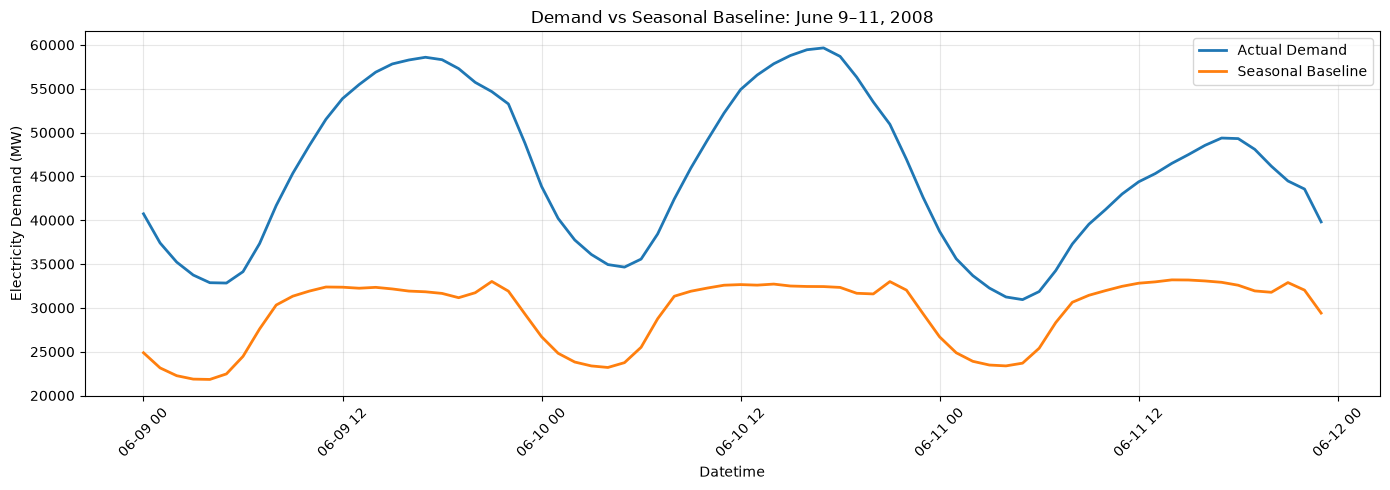

Observations: 72
Maximum actual demand: 59655.0 MW
Minimum actual demand: 30942.0 MW


In [5]:
import matplotlib.pyplot as plt

start_date = "2008-06-09"
end_date = "2008-06-12"

event_df = df[
    (df["Datetime"] >= start_date) &
    (df["Datetime"] < end_date)
].sort_values("Datetime")

plt.figure(figsize=(14, 5))

plt.plot(
    event_df["Datetime"],
    event_df["PJME_MW"],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    event_df["Datetime"],
    event_df["Seasonal_Baseline"],
    label="Seasonal Baseline",
    linewidth=2
)

plt.title("Demand vs Seasonal Baseline: June 9–11, 2008")
plt.xlabel("Datetime")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Observations:", len(event_df))
print("Maximum actual demand:", event_df["PJME_MW"].max(), "MW")
print("Minimum actual demand:", event_df["PJME_MW"].min(), "MW")

In [6]:
# Validate the event's actual demand against its seasonal baseline

event_df = event_df.copy()

event_df["Absolute_Difference"] = (
    event_df["PJME_MW"] - event_df["Seasonal_Baseline"]
).abs()

event_df["Difference_Percent"] = (
    (event_df["PJME_MW"] - event_df["Seasonal_Baseline"])
    / event_df["Seasonal_Baseline"].replace(0, float("nan"))
) * 100

print("===== EVENT VALIDATION =====")

print("\nActual demand (MW):")
display(event_df["PJME_MW"].describe().round(2))

print("\nSeasonal baseline (MW):")
display(event_df["Seasonal_Baseline"].describe().round(2))

print("\nDifference (MW):")
display(event_df["Absolute_Difference"].describe().round(2))

print(
    "\nMean percentage difference:",
    round(event_df["Difference_Percent"].mean(), 2),
    "%"
)

print("\nSample observations:")
display(
    event_df[
        [
            "Datetime",
            "PJME_MW",
            "Seasonal_Baseline",
            "Seasonal_Deviation",
            "Seasonal_Anomaly_Score"
        ]
    ].iloc[20:30]
)

===== EVENT VALIDATION =====

Actual demand (MW):


count       72.00
mean     45420.18
std       8892.51
min      30942.00
25%      37387.50
50%      45331.50
75%      53583.50
max      59655.00
Name: PJME_MW, dtype: float64


Seasonal baseline (MW):


count       72.00
mean     29505.27
std       3801.34
min      21836.00
25%      25476.62
50%      31697.00
75%      32393.25
max      33194.50
Name: Seasonal_Baseline, dtype: float64


Difference (MW):


count       72.00
mean     15914.91
std       6262.37
min       5931.50
25%      11000.75
50%      14278.75
75%      21550.00
max      27225.00
Name: Absolute_Difference, dtype: float64


Mean percentage difference: 53.34 %

Sample observations:


,Datetime,PJME_MW,Seasonal_Baseline,Seasonal_Deviation,Seasonal_Anomaly_Score
56430,2008-06-09 20:00:00,55724.0,31728.0,23996.0,5.417147
56431,2008-06-09 21:00:00,54669.0,33012.5,21656.5,7.100308
56432,2008-06-09 22:00:00,53264.0,31907.5,21356.5,7.187108
56433,2008-06-09 23:00:00,48782.0,29289.0,19493.0,6.814122
56434,2008-06-10 00:00:00,43857.0,26709.0,17148.0,5.700428
56435,2008-06-10 01:00:00,40201.0,24819.0,15382.0,5.509834
56436,2008-06-10 02:00:00,37746.0,23823.0,13923.0,5.828354
56437,2008-06-10 03:00:00,36094.0,23377.5,12716.5,5.395290
56438,2008-06-10 04:00:00,34938.0,23202.0,11736.0,4.973032
56439,2008-06-10 05:00:00,34650.0,23752.0,10898.0,4.796477


In [7]:
import pandas as pd
from pathlib import Path

# Load results independently
file_path = Path("../data/processed/anomaly_detection_results.csv")
df = pd.read_csv(file_path)

simple = df["Potential_Anomaly"].fillna(False).astype(bool)
seasonal = df["Seasonal_Potential_Anomaly"].fillna(False).astype(bool)

both_flagged = simple & seasonal
simple_only = simple & ~seasonal
seasonal_only = seasonal & ~simple
neither_flagged = ~simple & ~seasonal

total = len(df)

summary = pd.DataFrame({
    "Category": [
        "Flagged by both detectors",
        "Only rolling median + MAD",
        "Only seasonality-aware detector",
        "Flagged by neither"
    ],
    "Count": [
        int(both_flagged.sum()),
        int(simple_only.sum()),
        int(seasonal_only.sum()),
        int(neither_flagged.sum())
    ]
})

summary["Percentage"] = (summary["Count"] / total * 100).round(2)

display(summary)

,Category,Count,Percentage
0,Flagged by both detectors,59,0.04
1,Only rolling median + MAD,5002,3.44
2,Only seasonality-aware detector,5989,4.12
3,Flagged by neither,134316,92.40


In [8]:
from pathlib import Path
import pandas as pd

reports_dir = Path("../reports")
processed_dir = Path("../data/processed")

reports_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

summary_path = reports_dir / "anomaly_detector_comparison.csv"
summary.to_csv(summary_path, index=False)


event_path = processed_dir / "anomaly_event_validation.csv"
event_df.to_csv(event_path, index=False)


validation_overview = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Rolling Median + MAD flags",
        "Seasonality-aware flags",
        "Flags shared by both detectors",
        "Unique observations flagged by either detector"
    ],
    "Value": [
        len(df),
        int(simple.sum()),
        int(seasonal.sum()),
        int(both_flagged.sum()),
        int((simple | seasonal).sum())
    ]
})

overview_path = reports_dir / "anomaly_validation_summary.csv"
validation_overview.to_csv(overview_path, index=False)


for path in [summary_path, event_path, overview_path]:
    print(f"Saved: {path.resolve()}")
    print(f"Exists: {path.exists()}")

Saved: C:\Users\ASUS\GridSense\reports\anomaly_detector_comparison.csv
Exists: True
Saved: C:\Users\ASUS\GridSense\data\processed\anomaly_event_validation.csv
Exists: True
Saved: C:\Users\ASUS\GridSense\reports\anomaly_validation_summary.csv
Exists: True
